# Phase 3, part 2: population-aware sensor design

**Question this notebook answers.** If we weight the sensor-design objective by where people live, do the chosen sensor layouts reduce the error that people experience? At what cost to the area-wide error?

Everything is **synthetic**: five invented population fixtures on a small toy domain. No real population data was used.
Evidence: `results/phase3-population-toy/` (EXP-017, greedy selection) and `results/phase3-population-toy-exact/` (EXP-020, exact selection).
Findings: F-026 (corrected from F-023) and F-030. Doc: `docs/population-data.md`, `docs/phase3-findings.md`.

## What this shows / does not show

**Shows**
* Greedy selection is far from optimal at 2 to 4 sensors (median excess 6.7x, 8.9x and 3.0x of the best design objective).
* With exact selection, at 2 sensors on concentrated populations (`one_town`, `separated_settlements`), population-weighted layouts cut test population RMSE by 63 to 73 %, at 6 to 7 times the area RMSE.
* At 8 sensors population-weighted layouts are 9 to 12 % **worse** on test population RMSE, while looking 24 % better on the design cases. This is overfitting.

**Does not show**
* A Belauri-scale result. The toy domain is small and the populations are invented.
* Any effect with greedy selection (EXP-017): none is established.
* Statistical generality. EXP-020 has an effective sample of **4 source placements**. Intervals resample settings or cases, not placements, and are not confidence intervals for new scenarios.
* The test-error cost of the greedy layouts that Phase 2 used. It was not measured.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = Path("..").resolve()          # notebooks run with cwd = notebooks/
R = ROOT / "results"
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.4g}")

def show(path, width=760):
    """Show a saved PNG from results/. Skips quietly if the file is missing."""
    p = Path(path)
    if p.exists():
        display(Image(filename=str(p), width=width))
    else:
        print("missing:", p.relative_to(ROOT))

def load(path):
    p = Path(path)
    if not p.exists():
        print("missing:", p.relative_to(ROOT)); return None
    return pd.read_csv(p)

import inspect
from pravah import population

## 1. People per cell vs people per km^2

A raster can store **counts** (people per cell) or **density** (people per km^2). They differ by the cell area: `count = density x cell area`.
Regridding must conserve **counts**. Averaging densities over an area-weighted overlap does the same only when areas are equal. Mixing the two causes errors.
`pravah.population` keeps counts as the canonical form and converts with `counts_to_density` / `density_to_counts`.
The regrid uses area overlap (`regrid_counts`), so the total is conserved. `tests/test_population.py` checks this.

In [2]:
from pravah.config import Domain
from pravah.population import FIXTURES
print(inspect.signature(population.counts_to_density), "-> people/km^2")
print(inspect.signature(population.density_to_counts), "-> people/cell")
print("fixtures:", list(FIXTURES))

(counts: 'np.ndarray', grid: 'GridSpec') -> 'np.ndarray' -> people/km^2
(density: 'np.ndarray', grid: 'GridSpec') -> 'np.ndarray' -> people/cell
fixtures: ['uniform', 'one_town', 'separated_settlements', 'dense_core_sparse_surround', 'mixed_rural_urban']


## 2. The five fixtures (`src/pravah/population.py`)

Each fixture is a deterministic synthetic map of integer counts with an exact total (largest-remainder allocation). Seeds jitter the centres.

| Fixture | Shape |
|---|---|
| `uniform` | the same count in every cell |
| `one_town` | one Gaussian town (width 6 % of the shorter side) |
| `separated_settlements` | three Gaussian settlements of unequal size |
| `dense_core_sparse_surround` | 85 % of people in one core, 15 % spread evenly |
| `mixed_rural_urban` | two urban Gaussians (50 %) plus a lognormal rural field (50 %) |

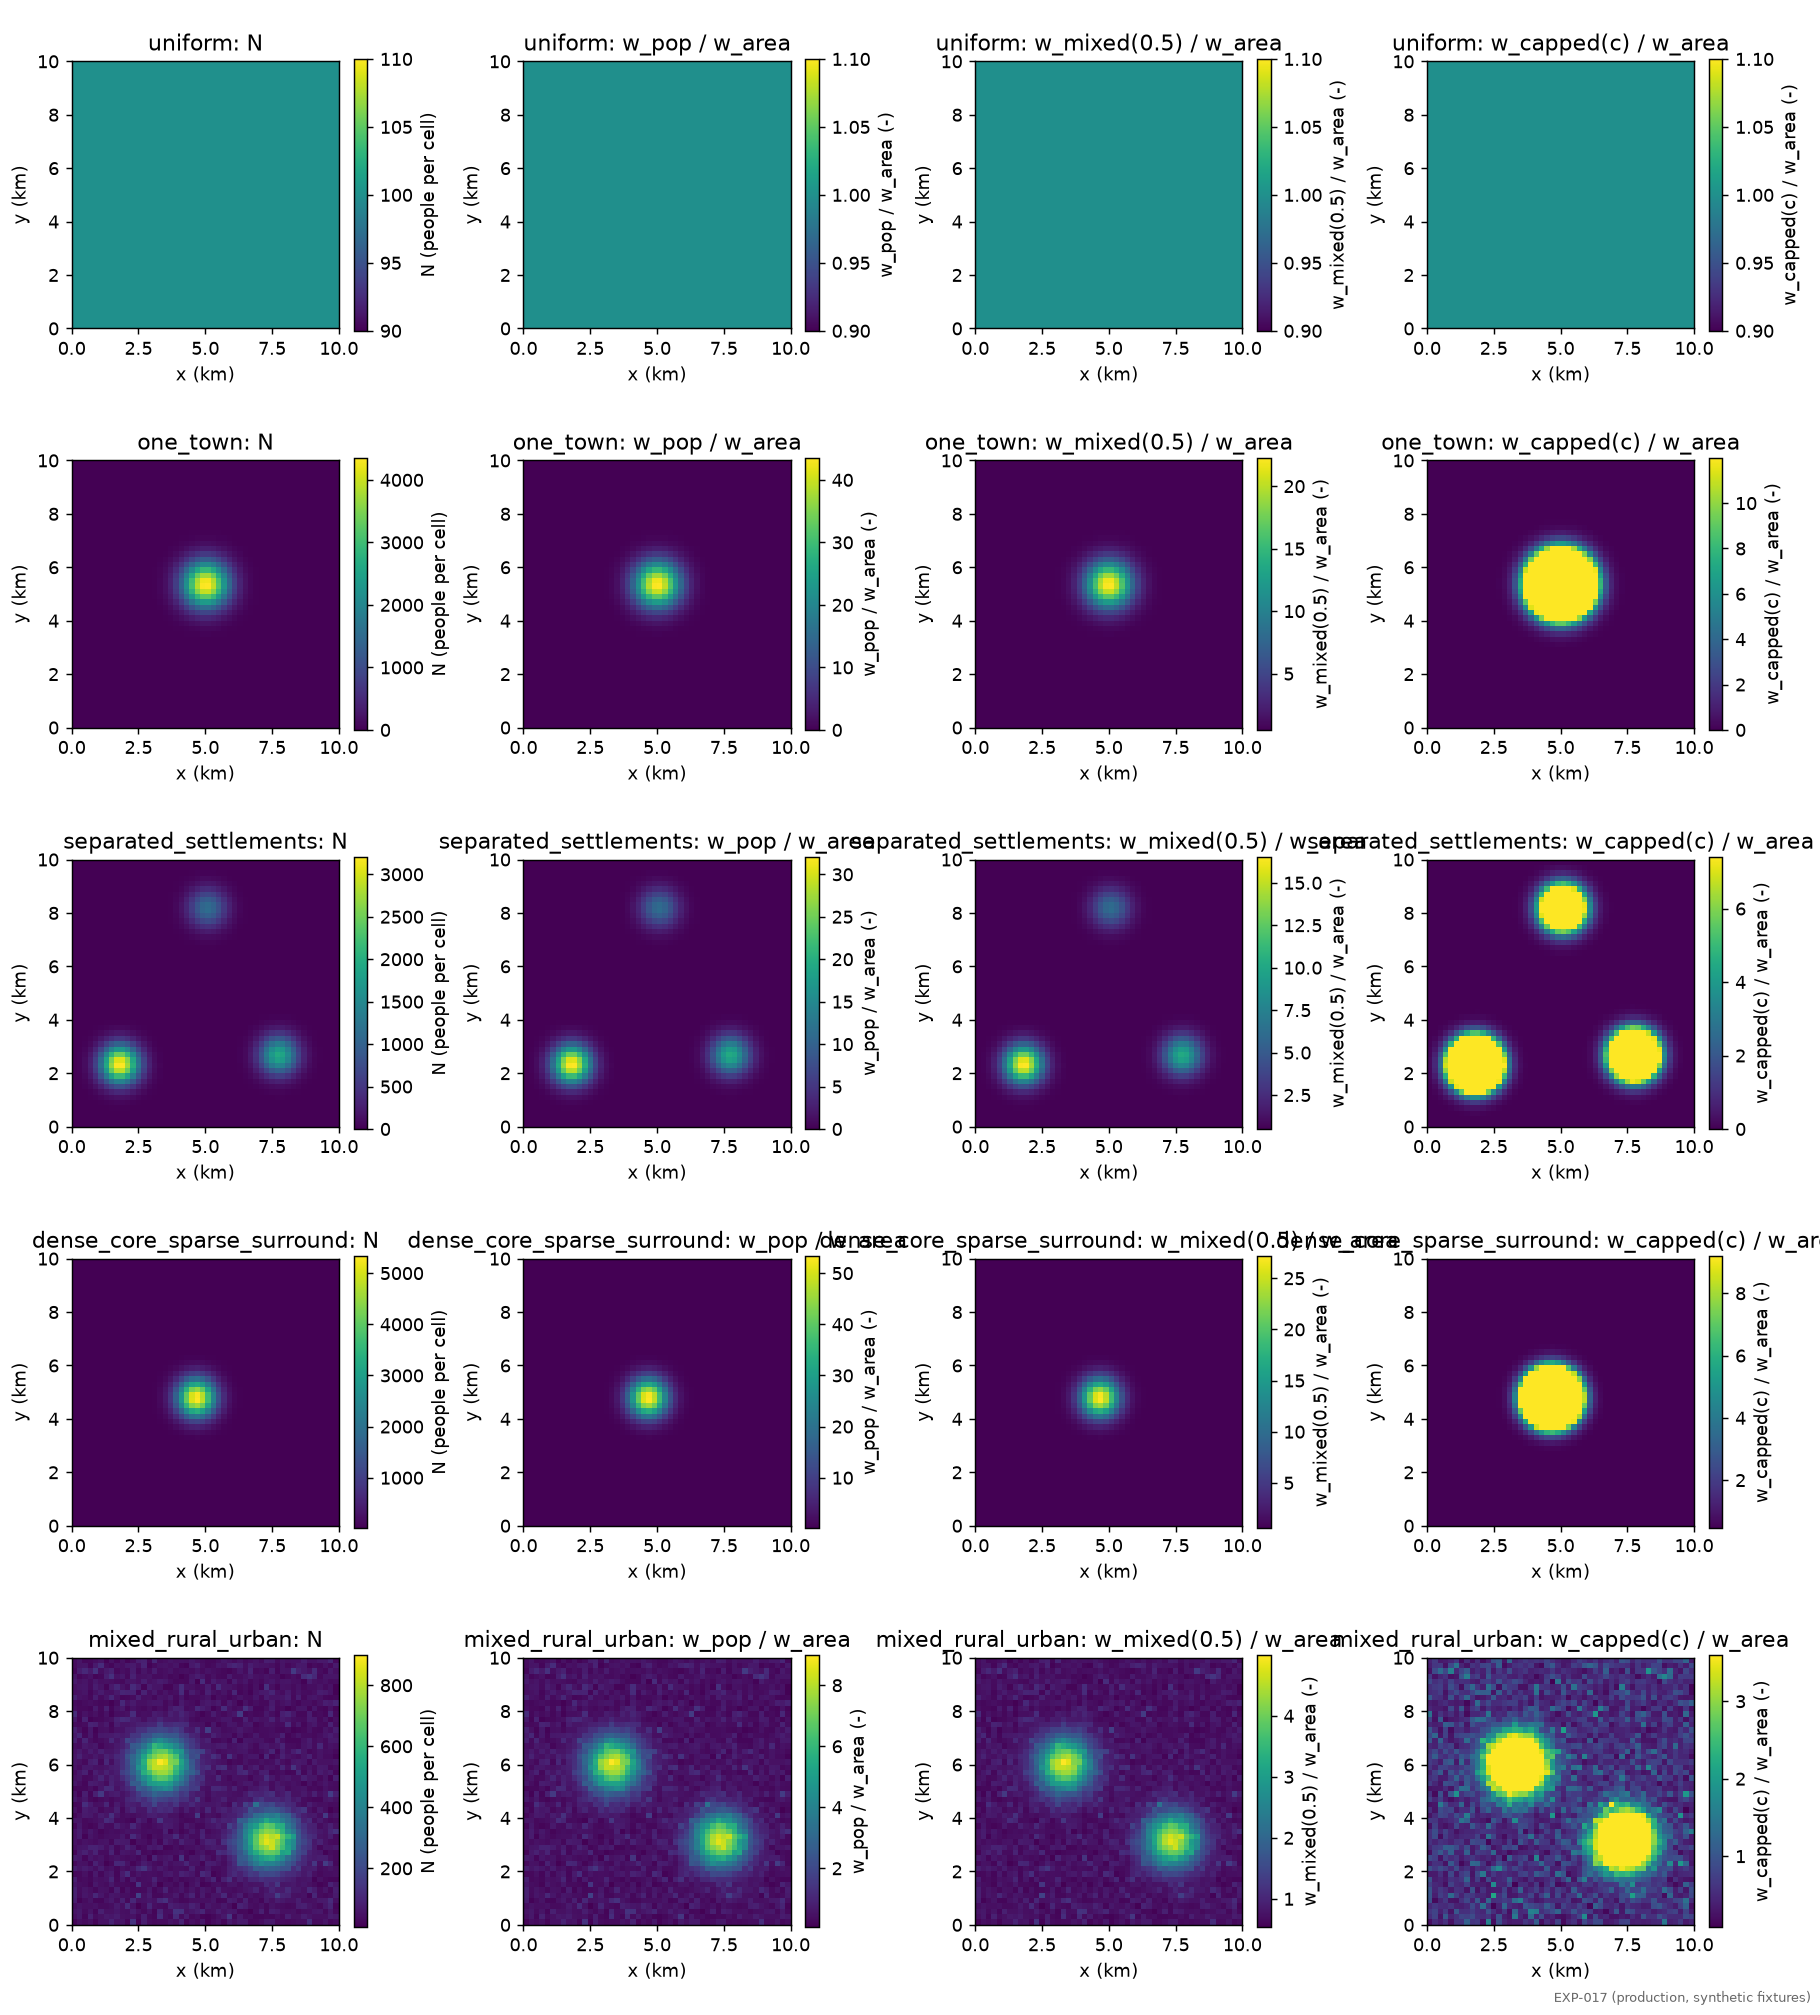

In [3]:
show(R / "phase3-population-toy" / "figures" / "fig1_population_weight_maps.png", 800)

## 3. Weights: area, population, mixed, capped

A design objective is a weighted mean squared error over cells: `MSE_w = sum_i w_i e_i^2` with `sum_i w_i = 1` (`e_i` is the field error in a cell, in the field's own units).
* **area**: `w_i = A_i / sum A` (every square kilometre counts the same).
* **population**: `w_i = N_i / sum N` (every person counts the same).
* **mixed(beta)**: `w = (1 - beta) w_area + beta w_pop`.
* **capped**: `w_i` proportional to `min(N_i, c * mean(N))`, so one dense core cannot dominate (`scripts/population_design.py`).

**Why a mixed objective is one weighted MSE.** The mean of two weighted sums is a weighted sum with the mixed weights:
`(1 - beta) sum w_area e^2 + beta sum w_pop e^2 = sum [(1 - beta) w_area + beta w_pop] e^2`.
So the existing machinery (`metrics.field_mse(weight=...)`) needs no change. We verify this numerically below.

In [4]:
rng = np.random.default_rng(0)
e = rng.normal(size=(20, 20)) ** 2                       # arbitrary squared-error map
N = rng.integers(0, 50, size=(20, 20)).astype(float)     # arbitrary counts
A = np.full((20, 20), 0.25)                              # km^2 per cell
beta = 0.5
w = population.mixed_weight(N, A, beta)
lhs = (1 - beta) * np.sum(A / A.sum() * e) + beta * np.sum(N / N.sum() * e)
print("weights sum to", w.sum(), "| mixed MSE:", np.sum(w * e), "| mix of the two MSEs:", lhs)

weights sum to 1.0 | mixed MSE: 1.0135670223203441 | mix of the two MSEs: 1.0135670223203441


## 4. EXP-017 (greedy selection): what was measured

Setting: toy domain, 5 fixtures, budgets 2, 3, 5 and 8 sensors, 16 test cases per fixture. Methods: area, population, mixed (beta 0.25, 0.5, 0.75), capped, spread, random.
Metrics are RMSE of the concentration field in test cases (same units as the field, relative scale here). `pop_rmse` weights by people; `area_rmse` weights by area.
The paired table gives mean differences against the area-weighted layout with a **percentile bootstrap over test cases**. That interval is not a confidence interval for new scenarios.

In [5]:
P = R / "phase3-population-toy"
pareto = load(P / "pareto.csv"); paired = load(P / "paired.csv")
t = pareto[pareto.method.isin(["area", "population", "capped"]) & (pareto.fixture == "one_town")]
t.pivot_table(index="budget", columns="method", values=["test_pop_rmse", "test_area_rmse"])

test_area_rmse                      test_pop_rmse                     
method           area    capped population          area    capped population
budget                                                                       
2            0.002805   0.01223    0.01223      0.001838  0.002378   0.002378
3           0.0007053  0.002249   0.002249      0.001303 0.0007988  0.0007988
5           0.0003025 0.0003166  0.0003166     0.0004743 0.0004457  0.0004457
8           0.0002632 0.0003095  0.0003095     0.0004158 0.0004394  0.0004394

In [6]:
pp = paired[(paired.method == "population") & (paired.metric == "pop_rmse")][["fixture", "budget", "mean_diff", "boot_lo", "boot_hi", "n_cases", "resolved"]]
print("population-weighted minus area-weighted layout, test pop_rmse (negative = population layout better):")
pp.reset_index(drop=True)

population-weighted minus area-weighted layout, test pop_rmse (negative = population layout better):


,fixture,budget,mean_diff,boot_lo,boot_hi,n_cases,resolved
0,dense_core_sparse_surround,2,0,0,0,16,False
1,dense_core_sparse_surround,3,0.000719,0.0001586,0.00162,16,True
2,dense_core_sparse_surround,5,9.38e-05,-2.303e-05,0.0001994,16,False
3,dense_core_sparse_surround,8,-2.992e-06,-3.027e-05,2.658e-05,16,False
4,mixed_rural_urban,2,0,0,0,16,False
5,mixed_rural_urban,3,0,0,0,16,False
6,mixed_rural_urban,5,0,0,0,16,False
7,mixed_rural_urban,8,1.468e-06,-1.639e-05,2.039e-05,16,False
8,one_town,2,0.0005399,-0.0006557,0.001731,16,False
9,one_town,3,-0.0005039,-0.0008002,-0.0002632,16,True


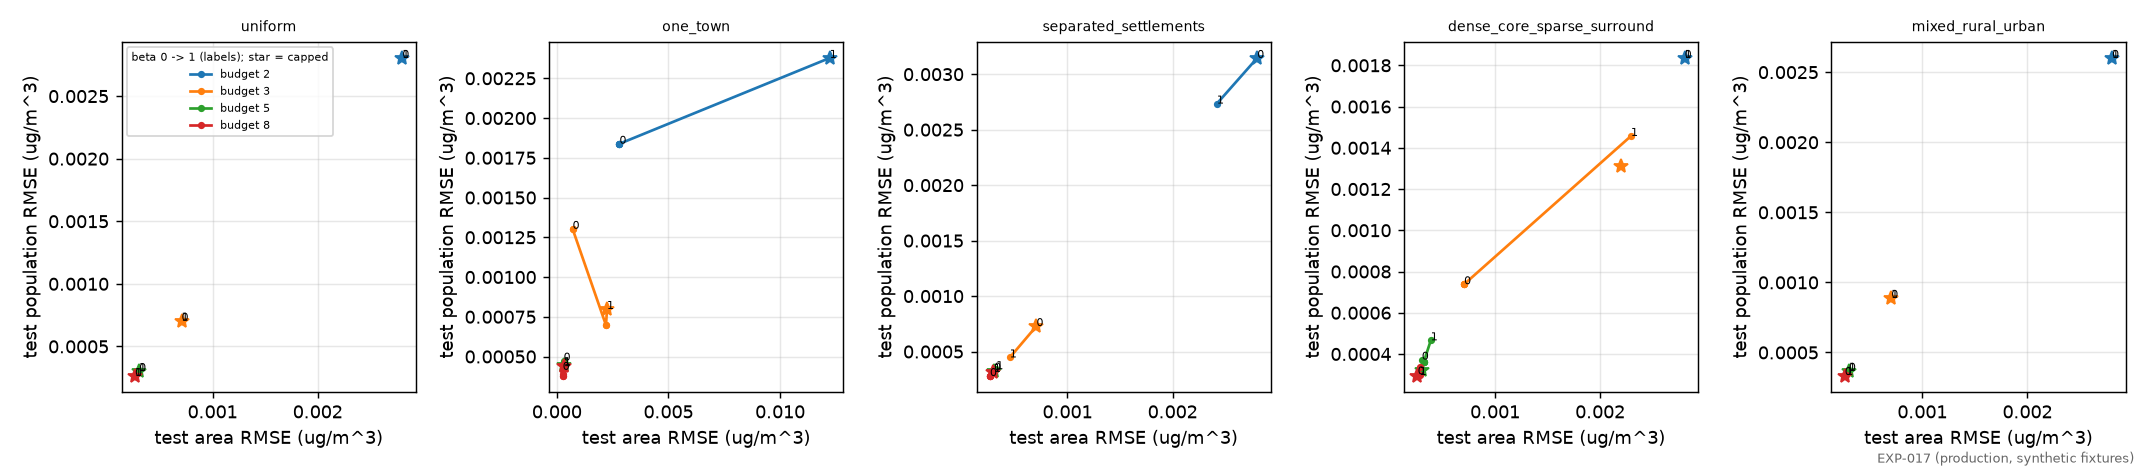

In [7]:
show(P / "figures" / "fig3_pareto.png", 800)

**Reading (F-026).** With greedy selection no objective effect is established. Greedy can pick a poor layout for any objective, so the objective effect is confounded with the search error.
The earlier claim "dense core is worse" (F-023) was a 1.3 % near-tie and was withdrawn.

## 5. EXP-020 (exact selection): what changed

EXP-020 finds the best layout for each design objective by exact enumeration or a verified search (batched bounded fits checked against scipy; see `tests/`).
Four source placements (0 to 3) times four concentrated fixtures times six population draws give 24 settings per fixture and budget (2, 3, 4, 5 and 8 sensors).
**Settings in one placement share test cases, so they are not independent. The effective sample for placement effects is 4.**

First: how suboptimal is greedy on the design objective?

In [8]:
E = R / "phase3-population-toy-exact"
sel = load(E / "selection.csv")
ex = sel[sel.method == "exact"]
print("Relative excess (greedy value - exact value) / exact value of the design objective; median over all objectives and settings:")
ex.groupby("budget").gap_rel.median().to_frame("median relative excess (x)")

Relative excess (greedy value - exact value) / exact value of the design objective; median over all objectives and settings:


,median relative excess (x)
budget,
2,6.676
3,8.854
4,2.964


In [9]:
gap = load(E / "design_gap.csv"); gg = gap[gap.method == "exact"]
print("Fraction of settings where greedy is not optimal, by design objective:")
gg.groupby(["budget", "objective"]).frac_greedy_suboptimal.mean().unstack()

Fraction of settings where greedy is not optimal, by design objective:


objective,area,capped,mixed_0.5,population
budget,,,,
2,1,0.8646,0.8438,0.8229
3,1,0.9583,1,0.9375
4,1,0.9896,1,0.9688


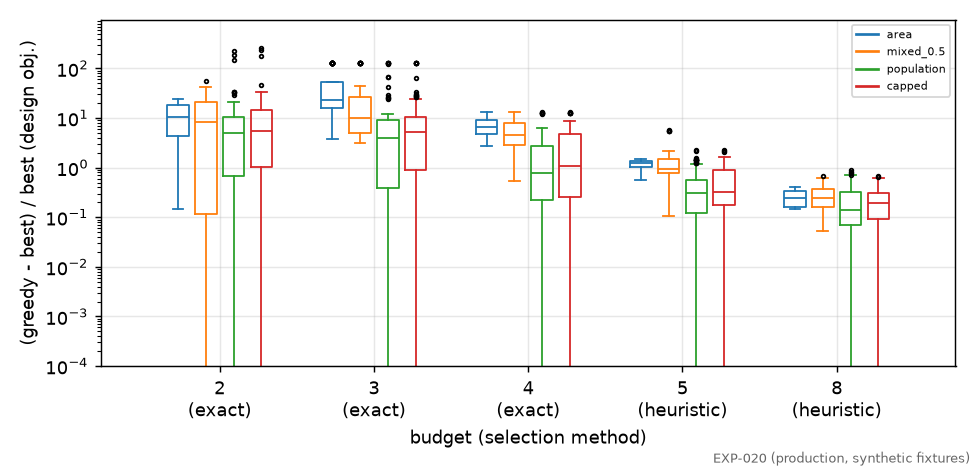

In [10]:
show(E / "figures" / "fig2_greedy_vs_exact_gap.png", 760)

The median relative excess is 6.7 (2 sensors), 8.9 (3) and 3.0 (4), the numbers in F-030: greedy is far from optimal on the design objective at small budgets. Phase 2 small-budget layouts used greedy. Read their rankings with this in mind.
The cost of this gap in **test** error was not measured.

## 6. Pareto and paired tables with exact selection

Pareto table: test errors per objective and budget. Paired table: each objective minus the area objective, mean difference over 24 settings and a bootstrap interval over **settings**.
Negative `pop_rmse` difference means the population-aware layout is better for people. `area_rmse` shows the cost.

In [11]:
par = load(E / "pareto.csv"); pai = load(E / "paired.csv")
a = pai[(pai.subset == "all") & (pai.objective == "population") & pai.metric.isin(["pop_rmse", "area_rmse"])]
tab = a.pivot_table(index=["type", "budget"], columns="metric", values=["mean_diff", "boot_lo", "boot_hi"])
tab.round(6)

boot_hi             boot_lo           mean_diff          
metric                            area_rmse  pop_rmse area_rmse  pop_rmse area_rmse  pop_rmse
type                       budget                                                            
dense_core_sparse_surround 2       0.000433  -8.7e-05 -0.000118 -0.000473  0.000153 -0.000266
                           3        2.6e-05     8e-06     5e-06     2e-06   1.5e-05     5e-06
                           4         -1e-06    -1e-06  -2.8e-05  -1.5e-05  -1.3e-05    -7e-06
                           5          1e-06     9e-06  -2.1e-05    -6e-06    -9e-06     1e-06
                           8        5.7e-05     3e-05   2.4e-05   1.4e-05     4e-05   2.2e-05
mixed_rural_urban          2       0.000533  0.000195  -9.4e-05 -0.000326  0.000208  -6.2e-05
                           3              0         0         0         0         0         0
                           4         -1e-06    -3e-06    -5e-05  -4.5e-05  -2.4e-05  -2.3e-05
                           5          7e-06     1e-06  -1.5e-05    -9e-06    -3e-06    -3e-06
                           8        4.9e-05   4.1e-05   2.2e-05   1.7e-05   3.5e-05   2.8e-05
one_town                   2        0.01497 -0.000512  0.009988 -0.001113   0.01249 -0.000807
                           3        0.01434   1.6e-05  0.008208     2e-06   0.01128     9e-06
                           4        0.01249    -3e-06  0.005162  -1.8e-05   0.00871    -1e-05
                           5         0.0113     2e-05  0.004862    -8e-06   0.00802     5e-06
                           8        0.00607   2.3e-05  0.001062     7e-06  0.003316   1.4e-05
separated_settlements      2        0.01285 -0.001146  0.006803 -0.001766  0.009863 -0.001439
                           3        0.01424    -1e-05  0.008175  -2.8e-05   0.01128  -1.9e-05
                           4        0.01376    -2e-05  0.007892  -3.7e-05   0.01089  -2.9e-05
                           5        0.01344  -1.6e-05   0.00763  -4.6e-05   0.01061    -3e-05
                           8       0.007807     6e-06  0.003244  -2.9e-05   0.00545  -1.2e-05

In [12]:
# relative change vs the area layout, from pareto.csv (mean over fixtures x budget): population objective
pv = par.pivot_table(index=["type", "budget"], columns="objective", values=["pop_rmse", "area_rmse"])
rel = pd.DataFrame({
    "pop_rmse change (%)": 100 * (pv[("pop_rmse", "population")] / pv[("pop_rmse", "area")] - 1),
    "area_rmse ratio (x)": pv[("area_rmse", "population")] / pv[("area_rmse", "area")]})
rel.round(2)

pop_rmse change (%)  area_rmse ratio (x)
type                       budget                                          
dense_core_sparse_surround 2                    -18.72                 1.07
                           3                      2.06                 1.05
                           4                     -3.15                 0.96
                           5                      0.33                 0.97
                           8                     12.14                 1.16
mixed_rural_urban          2                      -3.3                  1.1
                           3                         0                    1
                           4                     -7.25                 0.93
                           5                        -1                 0.99
                           8                     11.56                 1.14
one_town                   2                    -62.66                 6.96
                           3                      4.59                35.45
                           4                     -5.08                27.11
                           5                      2.61                26.11
                           8                      9.11                14.32
separated_settlements      2                    -73.46                 5.71
                           3                     -5.22                35.47
                           4                     -8.42                33.64
                           5                     -9.37                 34.2
                           8                     -4.36                 22.9

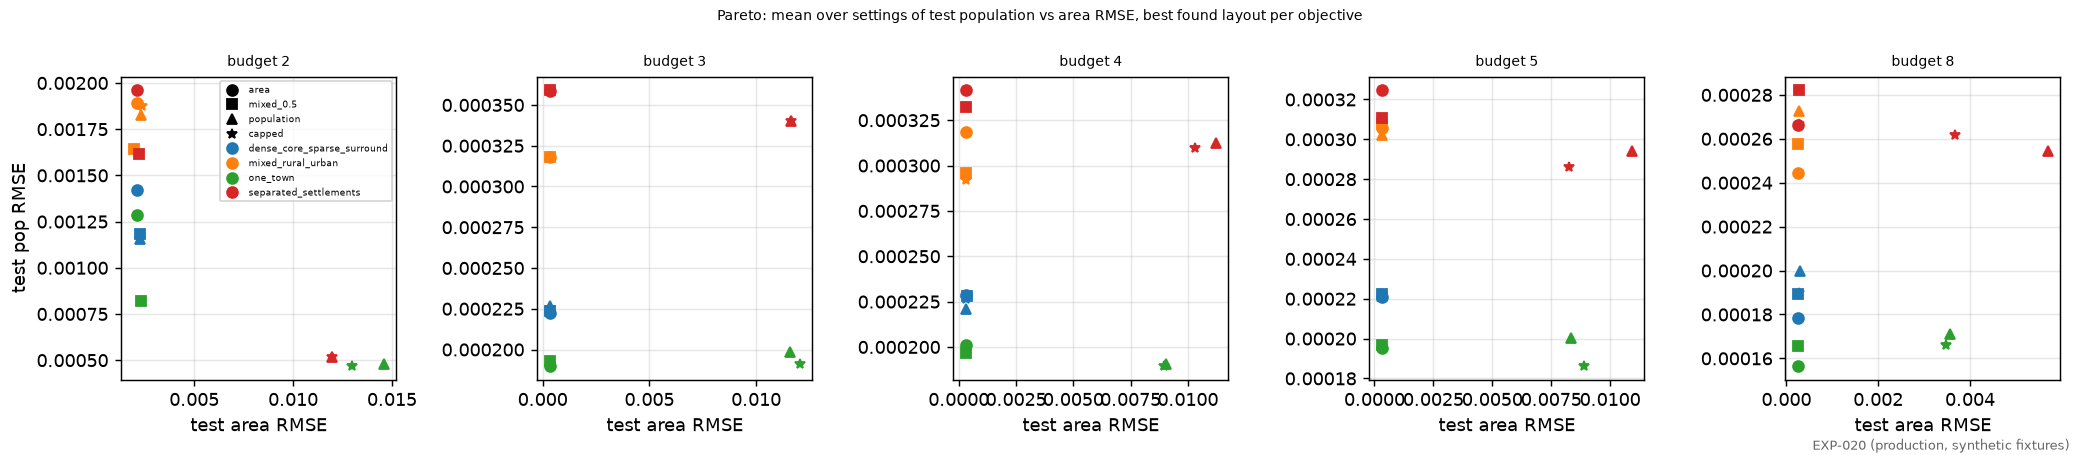

In [13]:
show(E / "figures" / "fig4_pareto.png", 800)

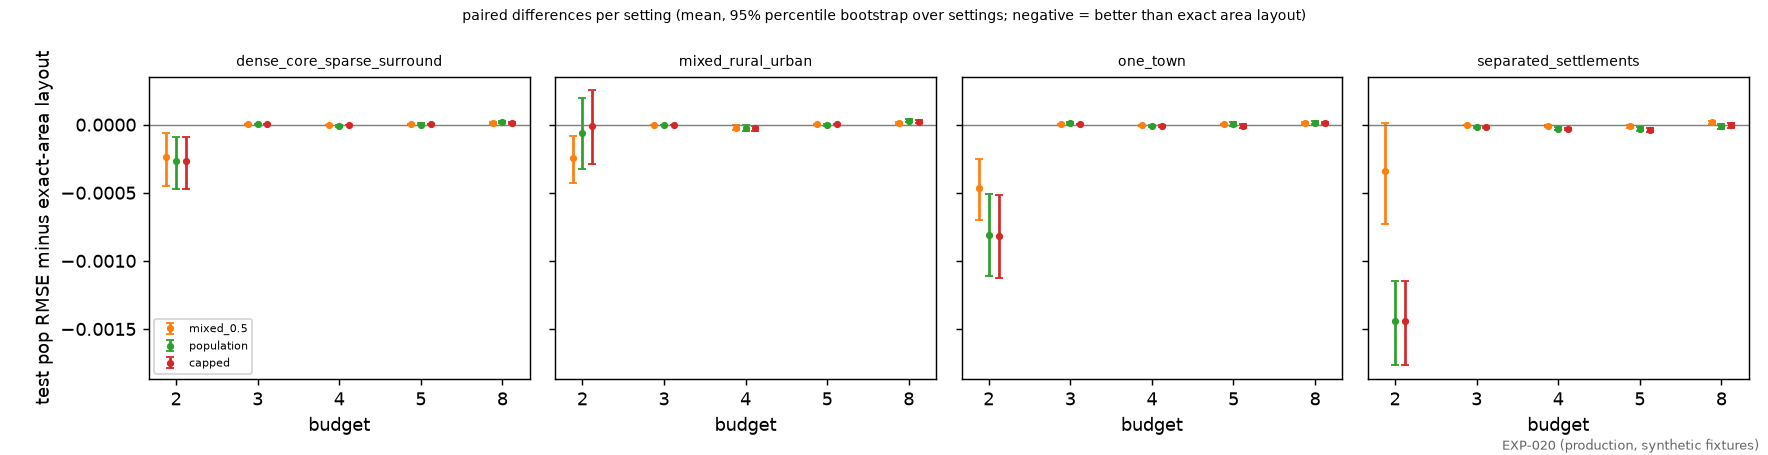

In [14]:
show(E / "figures" / "fig3_paired_differences.png", 800)

**Reading (F-030).**
* **Small budget, concentrated populations.** At 2 sensors on `one_town` and `separated_settlements` the population-weighted layout cuts test population RMSE by 63 and 73 % and raises area RMSE by 7.0 and 5.7 times. On `dense_core_sparse_surround` and `mixed_rural_urban` the gain is 19 % and 3 %.
* **Cost.** The area error grows a lot. A mixed objective (beta = 0.5) is the gentler compromise.
* **8 sensors.** The sign flips on three fixtures. Test population RMSE is 9 to 12 % higher (`one_town`, `dense_core_sparse_surround`, `mixed_rural_urban`), while the design-case objective looks 24 % better. The layout fits the design cases too closely.
* **3 to 5 sensors.** The change in test population RMSE is small (about -9 % to +5 % in the table) while area RMSE is 14 to 35 times larger on `one_town` and `separated_settlements`. The cost is large and the gain is not clear.
* **Near-ties.** Many objective pairs give almost the same layout value (`near_ties.csv`, below). A near-tie is not a result.

Share of (setting, budget) cases that are near-ties between objective pairs: 0.479


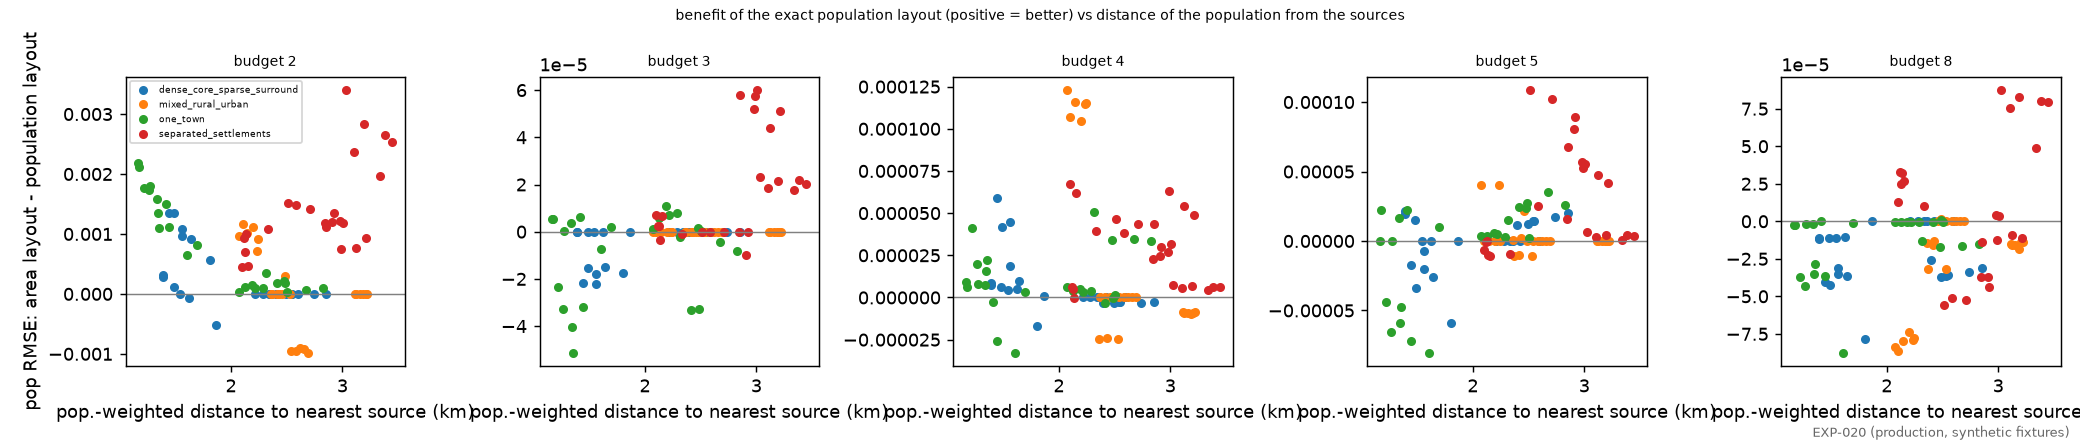

In [15]:
nt = load(E / "near_ties.csv")
print("Share of (setting, budget) cases that are near-ties between objective pairs:", round(nt.tie.mean(), 3))
show(E / "figures" / "fig1_benefit_vs_distance.png", 700)

The figure above relates the benefit to how far the population centroid is from the source placement (a moderator). With 4 placements the correlation is a description, not a test.

## 7. Follow-up: EXP-022 (exact greedy controls), if available

In [16]:
X = R / "phase3-population-toy-exact-greedy"
csvs = sorted(X.glob("*.csv")) if X.exists() else []
if csvs:
    for f in csvs[:6]:
        print("==", f.name); display(pd.read_csv(f).head(8))
    for p in sorted((X / "figures").glob("*.png")): show(p, 700)
else:
    print("EXP-022 has no result tables yet (run not finished or not in the repository):", X.relative_to(ROOT))

EXP-022 has no result tables yet (run not finished or not in the repository): results/phase3-population-toy-exact-greedy


## Limitations

* Synthetic fixtures on a toy domain. No real population raster (WorldPop, GHS-POP) and no Belauri-scale design. EXP-016 is specified, not run.
* **Effective sample of 4 source placements.** Bootstrap intervals are over settings (or over test cases in EXP-017). They are not confidence intervals for new scenarios.
* The area-weighted exact layout is the reference. A design-split control and the uniform fixture were requested by review and are not done in EXP-020.
* Greedy layouts scored on test error were not measured, so "exact beats greedy on test" is **not** shown.
* The mixed objective is a user choice of beta. The data do not say which beta is right.

Next: `09_phase3_winds_and_uncertainty.ipynb`.